# How random forests really work: building one from scratch

## What are we building?
A **random forest** that predicts whether a Titanic passenger survived, built step by step from the simplest possible rule up to the real thing:

1. **A "OneR" baseline**: a single yes/no question about a single column.
2. **A decision tree**: a flowchart of yes/no questions, found automatically.
3. **A random forest**: many trees voting together.

It is the same Titanic problem as the previous two notebooks, but this time with a completely different kind of model.

## Why are we building it?
- For **tabular data** (spreadsheet-like data such as Titanic), *ensembles of decision trees* (random forests, gradient boosting) are often as good as or better than neural networks, and they are far easier to set up.
- They need **much less preparation**: no scaling of columns, no dummy variables, and a small `log()` is not even necessary. That is why this notebook has so little data cleaning compared with the previous ones.
- A random forest is not magic. By writing the key parts ourselves (how to choose a split, how to grow a tree, how to average many trees) you will see it is built from a few simple ideas.

This follows Jeremy Howard's Kaggle notebook [How random forests really work](https://www.kaggle.com/code/jhoward/how-random-forests-really-work), adapted to run on your Windows machine.

## Roadmap

| Section | What we do | Key idea |
|---|---|---|
| 1. Setup and data | load data, turn text into category codes | trees only care about the *order* of numbers |
| 2. Binary splits | split the passengers into two groups by one rule | the building block of a tree |
| 3. Scoring a split | invent a number that says how "clean" a split is | impurity |
| 4. OneR | automatically find the single best split | a surprisingly strong baseline |
| 5. Decision tree | repeat the split inside each group | a tree is splits stacked on splits |
| 6. Random forest | train many different trees and average them | averaging cancels out random errors |

**What to expect:** on a dataset this small the fancier models improve only a few percentage points over the simplest one, and a different validation split can reorder them. The lesson is understanding *how* they work, and learning to always check a simple baseline first.

## 1. Setup

We import the tools we need. Unlike the last notebook there is no fastai here: random forests come from **scikit-learn** (`sklearn`), the standard Python library for classic machine learning.

| Import | What it gives us |
|---|---|
| `numpy` (`np`) | fast arrays and maths |
| `pandas` (`pd`) | tables (`DataFrame`) |
| `matplotlib.pyplot` (`plt`) | drawing charts |
| `seaborn` (`sns`) | prettier statistical charts built on matplotlib |
| `Path` | file paths that work on any operating system |

`np.set_printoptions(linewidth=130)` just lets numpy print wider lines.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.set_printoptions(linewidth=130)   # print wider numpy output

## 2. Data preprocessing

### Load the data
Same logic as before: on Kaggle the data is already provided; on your computer we download it once and reuse it.

In [2]:
iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')   # set only on Kaggle's servers

if iskaggle:
    path = Path('../input/titanic')
else:
    path = Path('titanic')
    if not path.exists():                                  # download only once
        import zipfile, kaggle
        kaggle.api.competition_download_cli(str(path))
        zipfile.ZipFile(f'{path}.zip').extractall(path)

df = pd.read_csv(path/'train.csv')        # training passengers (we know who survived)
tst_df = pd.read_csv(path/'test.csv')     # test passengers (we must predict)
modes = df.mode().iloc[0]                 # the most common value of every column, used to fill blanks

### Clean the data, trees style

We do much the same cleaning as in the previous notebooks (fill blanks, take `log` of fare), with **one important difference**: we do *not* create dummy (0/1) columns for text columns.

Instead we convert them to a pandas **categorical** type. Internally pandas keeps a list of the possible values (the *categories*) and stores each row as a whole-number **code**, the position in that list. For example, with categories `['female', 'male']`, female is stored as `0` and male as `1`.

Why is that OK? A decision tree only asks questions of the form "is this number `<=` some threshold?". With the codes above, the question "is Sex `<=` 0?" means "is the passenger female?". No dummy columns needed.

We list the categories ourselves instead of letting pandas guess them from each file separately. That guarantees the training and test sets use **exactly the same codes** (a subtle bug waiting to happen otherwise: if the test file happened to be missing one category, the codes would shift and the model would silently get the wrong meaning).

In [3]:
def proc_data(df):
    df['Fare'] = df.Fare.fillna(0)                 # the test set has one blank fare: use 0
    df.fillna(modes, inplace=True)                 # fill every other blank with the column's most common value
    df['LogFare'] = np.log1p(df['Fare'])           # log(1 + fare): makes fare charts easier to read
    # Fix the category lists so train and test get identical codes: C=0, Q=1, S=2 and female=0, male=1
    df['Embarked'] = pd.Categorical(df.Embarked, categories=['C', 'Q', 'S'])
    df['Sex'] = pd.Categorical(df.Sex, categories=['female', 'male'])

proc_data(df)        # clean the training data
proc_data(tst_df)    # clean the test data in exactly the same way

Now we list which columns are which:

- `cats`: the **categorical** inputs (stored as codes).
- `conts`: the **continuous** (number) inputs. We now put `Pclass` here instead of treating it as a category, because 1st, 2nd and 3rd class have a natural *order*, and a tree only cares about order.
- `dep`: the **dependent** variable, i.e. the thing we want to predict.

In [4]:
cats = ["Sex", "Embarked"]                                # category columns
conts = ['Age', 'SibSp', 'Parch', 'LogFare', "Pclass"]    # number columns
dep = "Survived"                                          # what we want to predict

Even though `Sex` is now categorical, pandas still *displays* the original words:

In [5]:
df.Sex.head()   # shows the words, plus the list of categories at the bottom

0      male
1    female
2    female
3    female
4      male
Name: Sex, dtype: category
Categories (2, str): ['female', 'male']

...but behind the scenes each row is stored as a code. We can see the codes with `.cat.codes`:

In [6]:
df.Sex.cat.codes.head()   # 0 = female, 1 = male

0    1
1    0
2    0
3    0
4    1
dtype: int8

## 3. Binary splits

A **decision tree** is built from one simple operation, the **binary split**: put every row into one of two groups depending on whether a column is above or below a threshold.

For example, splitting on `Sex` with threshold `0.5` puts females (code 0) on one side and males (code 1) on the other. Does that make useful groups? Let's look: the left chart shows the survival rate in each group, the right chart shows how many passengers are in each group.

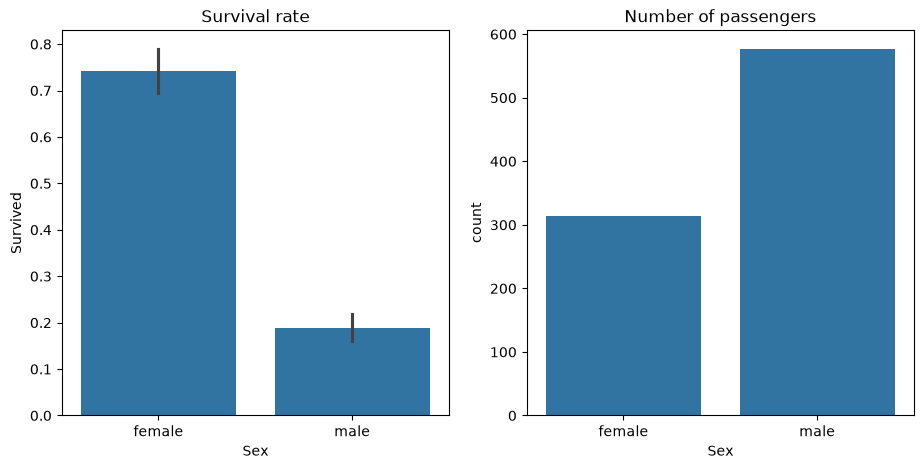

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5))                                      # one row, two charts side by side
sns.barplot(data=df, y=dep, x="Sex", ax=axs[0]).set(title="Survival rate")          # average of Survived per sex (= survival rate)
sns.countplot(data=df, x="Sex", ax=axs[1]).set(title="Number of passengers");       # how many passengers in each group

The two groups have **very different survival rates** (high for females, low for males) and both groups are large. That is exactly what a good split looks like: groups that differ a lot from each other, each with plenty of rows.

### A first, extremely simple model
"All females survive, no males do." To test it honestly we first need a **validation set**: passengers we hold back and never look at while building the model.

- `train_test_split(df, test_size=0.25, random_state=42)` randomly keeps 25% of the rows for validation. `random_state=42` makes the split repeatable.
- We then replace the category columns by their integer codes, because scikit-learn models need numbers.

In [8]:
from sklearn.model_selection import train_test_split

trn_df, val_df = train_test_split(df, test_size=0.25, random_state=42)    # 75% to train on, 25% to check on
trn_df[cats] = trn_df[cats].apply(lambda x: x.cat.codes)                   # words -> integer codes (training rows)
val_df[cats] = val_df[cats].apply(lambda x: x.cat.codes)                   # ...and the validation rows
len(trn_df), len(val_df)

(668, 223)

Next, split each table into the inputs (`xs`, the independent variables) and the answer (`y`, the dependent variable). The test set has no `Survived` column, so for it the function returns `None` for `y`.

In [9]:
def xs_y(df):
    xs = df[cats + conts].copy()                        # just the input columns, in a fixed order
    y = df[dep] if dep in df else None                  # the answer column (the test set doesn't have one)
    return xs, y

trn_xs, trn_y = xs_y(trn_df)    # training inputs and answers
val_xs, val_y = xs_y(val_df)    # validation inputs and answers

Our rule "females survive, males don't" is one line. `Sex == 0` is True for females, so True means "predict survived":

In [10]:
preds = val_xs.Sex == 0   # True (predict survived) for females, False for males

**How do we score it?** We use the **mean absolute error (MAE)**: the average gap between the prediction and the truth. Because both are 0 or 1, every wrong prediction contributes 1 and every right one contributes 0, so MAE here is simply the **fraction of wrong predictions** (the error rate). Accuracy is `1 - MAE`. Lower MAE is better.

In [11]:
from sklearn.metrics import mean_absolute_error

mean_absolute_error(val_y, preds)   # fraction of validation passengers we got wrong

0.21524663677130046

We can also try splitting on a continuous column. For `LogFare` we compare how the fares of those who died and those who survived are distributed:
- the **boxen plot** (left) shows the quantiles of `LogFare` for each outcome,
- the **density plot** (right) shows the overall spread of `LogFare`.

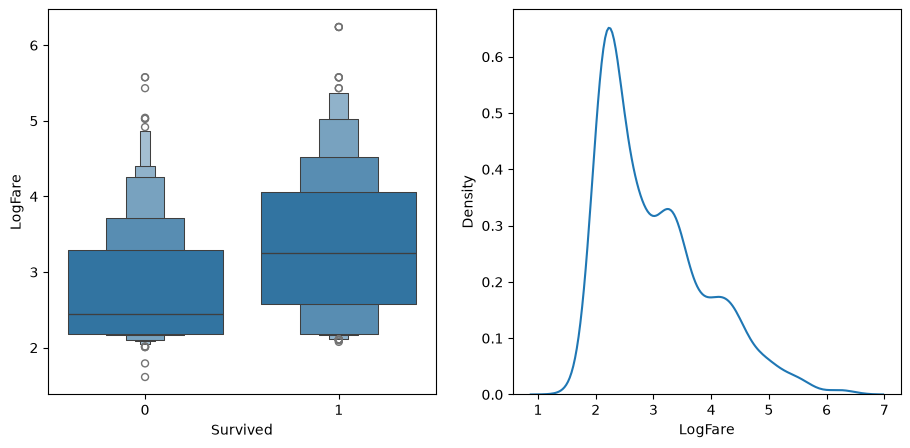

In [12]:
df_fare = trn_df[trn_df.LogFare > 0]    # ignore the few free tickets (log fare 0) so they don't distort the chart
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
sns.boxenplot(data=df_fare, x=dep, y="LogFare", ax=axs[0])     # LogFare quantiles for died (0) vs survived (1)
sns.kdeplot(data=df_fare, x="LogFare", ax=axs[1]);             # smooth histogram of LogFare

Survivors tend to have paid more. A simple rule from this chart is "predict survived if `LogFare` is above 2.7" (2.7 is a reasonable-looking dividing line read off the chart). Let's test it:

In [13]:
preds = val_xs.LogFare > 2.7              # predict survived when the fare was high
mean_absolute_error(val_y, preds)         # compare this error with the Sex-only rule above

0.336322869955157

The fare rule makes more mistakes than the `Sex` rule. Trying splits by hand is slow, so we want the computer to compare splits for us. For that we need a **number** that says how good a split is.

## 4. Scoring a split: impurity

A good split makes two groups where **the rows inside each group are alike** (for example almost everyone in the group survived). We call a group that is mixed 50/50 *impure*, and one that is all the same *pure*.

We can measure how mixed a group is with the **standard deviation** of the answer column (0 or 1): if everyone in the group has the same answer, the standard deviation is 0; if the group is an even mix, it is as large as it gets (0.5). Then we multiply by the group's size, because a big group matters more than a small one.

`_side_score(side, y)` does this for one side of a split:
- `side` is a True/False mask saying which rows belong to this side,
- `side.sum()` counts the rows on this side,
- `y[side].std()` is the standard deviation of the answers of just those rows.

In [13]:
def _side_score(side, y):
    tot = side.sum()                 # number of rows on this side of the split
    if tot <= 1: return 0            # a group of 0 or 1 rows has no spread (and std() would fail)
    return y[side].std() * tot       # how mixed the group is, weighted by how big it is

`score(col, y, split)` evaluates a whole split: rows with `col <= split` go to the left-hand side (lhs), everything else (`~lhs`, the opposite) goes to the right-hand side. We add the two sides' scores and divide by the total number of rows so the result doesn't depend on dataset size.

**Lower score = purer groups = better split.**

In [15]:
def score(col, y, split):
    lhs = col <= split                                          # True for rows that go to the left group
    return (_side_score(lhs, y) + _side_score(~lhs, y)) / len(y)   # ~lhs = "not lhs" = the right group

The score for the split on `Sex` (at 0.5), and the score for the split on `LogFare` (at 2.7):

In [16]:
print("Sex     <= 0.5 :", score(trn_xs["Sex"], trn_y, 0.5))
print("LogFare <= 2.7 :", score(trn_xs["LogFare"], trn_y, 2.7))

Sex     <= 0.5 : 0.40787530982063946
LogFare <= 2.7 : 0.47180873952099694


`Sex` has the lower (better) score, which agrees with the error rates we measured above. The score gives us the same ranking without having to build a whole model for each idea.

The original notebook uses an interactive slider here. To keep this notebook working everywhere, we instead try several thresholds for one column and print their scores:

In [17]:
for split in [5, 10, 15.5, 20, 30, 40]:                                # candidate thresholds for Age
    print(f"Age <= {split:>4}: score = {score(trn_xs['Age'], trn_y, split):.4f}")

Age <=    5: score = 0.4788
Age <=   10: score = 0.4813
Age <= 15.5: score = 0.4811
Age <=   20: score = 0.4850
Age <=   30: score = 0.4853
Age <=   40: score = 0.4858


## 5. Let the computer find the best split: OneR

Rather than trying thresholds by hand, we try **every** value that appears in a column as a possible threshold and keep the one with the lowest score.

First, step by step for `Age`: list all distinct ages, sorted.

In [18]:
nm = "Age"
col = trn_xs[nm]                      # the Age column of the training inputs
unq = np.sort(col.unique())           # every distinct age, in increasing order. Each is a candidate threshold
unq

array([ 0.42,  0.67,  0.75,  0.83,  0.92,  1.  ,  2.  ,  3.  ,  4.  ,  5.  ,  6.  ,  7.  ,  8.  ,  9.  , 10.  , 11.  , 12.  ,
       13.  , 14.  , 14.5 , 15.  , 16.  , 17.  , 18.  , 19.  , 20.  , 21.  , 22.  , 23.  , 24.  , 24.5 , 25.  , 26.  , 27.  ,
       28.  , 28.5 , 29.  , 30.  , 31.  , 32.  , 32.5 , 33.  , 34.  , 34.5 , 35.  , 36.  , 36.5 , 37.  , 38.  , 39.  , 40.  ,
       40.5 , 41.  , 42.  , 43.  , 44.  , 45.  , 45.5 , 46.  , 47.  , 48.  , 49.  , 50.  , 51.  , 52.  , 53.  , 54.  , 55.  ,
       55.5 , 56.  , 57.  , 58.  , 59.  , 60.  , 61.  , 62.  , 64.  , 65.  , 70.  , 70.5 , 74.  , 80.  ])

Now score every candidate and pick the best. `argmin()` returns the **position** of the smallest number in an array:

In [19]:
scores = np.array([score(col, trn_y, o) for o in unq])   # one score per candidate threshold
unq[scores.argmin()]                                      # the threshold with the lowest score = best age split

np.float64(6.0)

We wrap that into a function, `min_col`, that returns the best threshold and its score for any column. `dropna()` skips blanks so they can't be used as thresholds.

In [20]:
def min_col(df, nm):
    col, y = df[nm], df[dep]                                     # the column to split on, and the answers
    unq = col.dropna().unique()                                  # candidate thresholds
    scores = np.array([score(col, y, o) for o in unq])           # score of each candidate
    idx = scores.argmin()                                        # position of the best (lowest) score
    return unq[idx], scores[idx]                                 # (best threshold, its score)

min_col(trn_df, "Age")

(np.float64(6.0), np.float64(0.478316717508991))

Try it on **every** column. Each entry reads `column: (best threshold, score)`:

In [21]:
cols = cats + conts
{o: min_col(trn_df, o) for o in cols}   # dictionary comprehension: run min_col once per column

{'Sex': (np.int8(0), np.float64(0.40787530982063946)),
 'Embarked': (np.int8(0), np.float64(0.47883342573147836)),
 'Age': (np.float64(6.0), np.float64(0.478316717508991)),
 'SibSp': (np.int64(4), np.float64(0.4783740258817434)),
 'Parch': (np.int64(0), np.float64(0.4805296527841601)),
 'LogFare': (np.float64(2.4390808375825834), np.float64(0.4620823937736597)),
 'Pclass': (np.int64(2), np.float64(0.46048261885806596))}

The column with the lowest score is the best single question to ask. We have just re-invented the **OneR** ("One Rule") classifier: pick the single best column and threshold. It is very simple, but historically it held its own against much more complicated algorithms, so it makes an excellent **baseline**: a starting point every fancier model has to beat to justify its complexity.

Let's record the OneR error rate on the validation set so we can compare later models with it:

In [23]:
best_col, (best_split, _) = min(((c, min_col(trn_df, c)) for c in cols), key=lambda t: t[1][1])
print(f"OneR picks: {best_col} <= {best_split}")

oner_preds = val_xs[best_col] <= best_split          # for Sex <= 0 this means "female -> predict survived"
oner_err = mean_absolute_error(val_y, oner_preds)
print("OneR validation error:", round(oner_err, 4))

OneR picks: Sex <= 0
OneR validation error: 0.2152


## 6. Creating a decision tree

How can we improve OneR? **Split each of the two groups again.** Find the best question for females and the best question for males separately. Repeat that and you have a **decision tree**.

First remove `Sex` from the candidate columns (it is already used, and a binary column can't be split twice) and separate the training rows into the two groups:

In [25]:
other_cols = [c for c in cols if c != "Sex"]       # candidate columns for the next level of questions
ismale = trn_df.Sex == 1                           # True for males (code 1)
males, females = trn_df[ismale], trn_df[~ismale]   # two smaller tables
len(males), len(females)

(439, 229)

The best next question for **males**:

In [26]:
{o: min_col(males, o) for o in other_cols}

{'Embarked': (np.int8(0), np.float64(0.3875581870410906)),
 'Age': (np.float64(6.0), np.float64(0.3739828371010595)),
 'SibSp': (np.int64(4), np.float64(0.3875864227586273)),
 'Parch': (np.int64(0), np.float64(0.3874704821461959)),
 'LogFare': (np.float64(2.803360380906535), np.float64(0.3804856231758151)),
 'Pclass': (np.int64(1), np.float64(0.38155442004360934))}

...and for **females**:

In [27]:
{o: min_col(females, o) for o in other_cols}

{'Embarked': (np.int8(0), np.float64(0.4295252982857327)),
 'Age': (np.float64(50.0), np.float64(0.4225927658431649)),
 'SibSp': (np.int64(4), np.float64(0.42319212059713535)),
 'Parch': (np.int64(3), np.float64(0.4193314500446158)),
 'LogFare': (np.float64(4.256321678298823), np.float64(0.41350598332911376)),
 'Pclass': (np.int64(2), np.float64(0.3335388911567601))}

Reading the lowest score in each dictionary gives the next question for each group. Putting it together, the model now says: *"First ask whether the passenger is female or male; then, for each group, ask its own follow-up question."* That is a **decision tree** with two levels. We could keep going on each of the four resulting groups.

Instead of writing this loop by hand, scikit-learn's `DecisionTreeClassifier` does it for us.
- `max_leaf_nodes=4` stops growing when the tree has 4 end groups ("leaves"), like the two-level tree above.
- `.fit(trn_xs, trn_y)` is where the tree is built from the training data.
- `random_state=42` makes the result repeatable (ties between equally good splits are otherwise broken randomly).

In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree4 = DecisionTreeClassifier(max_leaf_nodes=4, random_state=42).fit(trn_xs, trn_y)

scikit-learn can draw the tree. (The original notebook uses an extra program called Graphviz for this; `plot_tree` draws with matplotlib, so nothing extra is needed.)

How to read each box:
- the first line is the **question** (rows answering "yes" go left, the rest go right),
- **gini** measures how mixed the group is (0 = everyone has the same outcome),
- **samples** is how many training passengers reached this box,
- **value** is `[number who died, number who survived]`,
- **class** is the prediction this box would make (the majority outcome),
- the colour is orange for mostly died and blue for mostly survived; darker means purer.

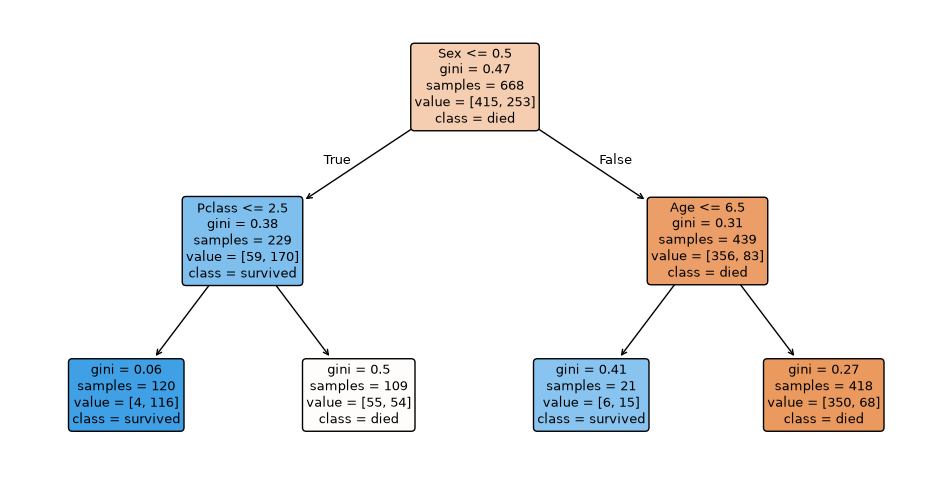

In [29]:
def draw_tree(t, xs, size=(12, 6)):
    fig, ax = plt.subplots(figsize=size)
    plot_tree(t, feature_names=list(xs.columns), class_names=['died', 'survived'],
              filled=True, rounded=True, precision=2, fontsize=9, ax=ax)   # draw the tree on our axes
    plt.show()

draw_tree(tree4, trn_xs)

It should have found the same questions we found by hand (compare the splits in the boxes with the dictionaries above).

### Gini impurity
The tree boxes show **gini**, an alternative to our standard-deviation score. It is the probability that, if you pick **two rows at random from a group, they have *different* outcomes**: 0 for a group where everybody has the same outcome, and at most 0.5 for a 50/50 mix. (The original notebook words this the other way round; the formula below is what matters.)

If `p` is the fraction who survived, then `1 - p² - (1-p)²` is the chance that two random rows differ. We use the whole `df` here just to illustrate:

In [30]:
def gini(cond):
    act = df.loc[cond, dep]                          # survival (0/1) of the passengers matching the condition
    return 1 - act.mean()**2 - (1 - act.mean())**2   # mean() = fraction who survived = p

print("gini of females:", round(gini(df.Sex == 'female'), 3))
print("gini of males  :", round(gini(df.Sex == 'male'), 3))

gini of females: 0.383
gini of males  : 0.306


Now how does the 4-leaf tree do on the validation set, compared to OneR?

In [31]:
tree4_err = mean_absolute_error(val_y, tree4.predict(val_xs))
print("OneR error  :", round(oner_err, 4))
print("tree4 error :", round(tree4_err, 4))

OneR error  : 0.2152
tree4 error : 0.2242


Differences this small are **not meaningful** here: with about 220 validation passengers, each single passenger changes the error by roughly 0.45 percentage points, so a few passengers either way can flip the ranking.

Maybe a bigger tree helps. We can't keep splitting forever: a group with only a handful of passengers gives unreliable predictions (and the tree would just memorise them). `min_samples_leaf=50` forbids any end group smaller than 50 passengers:

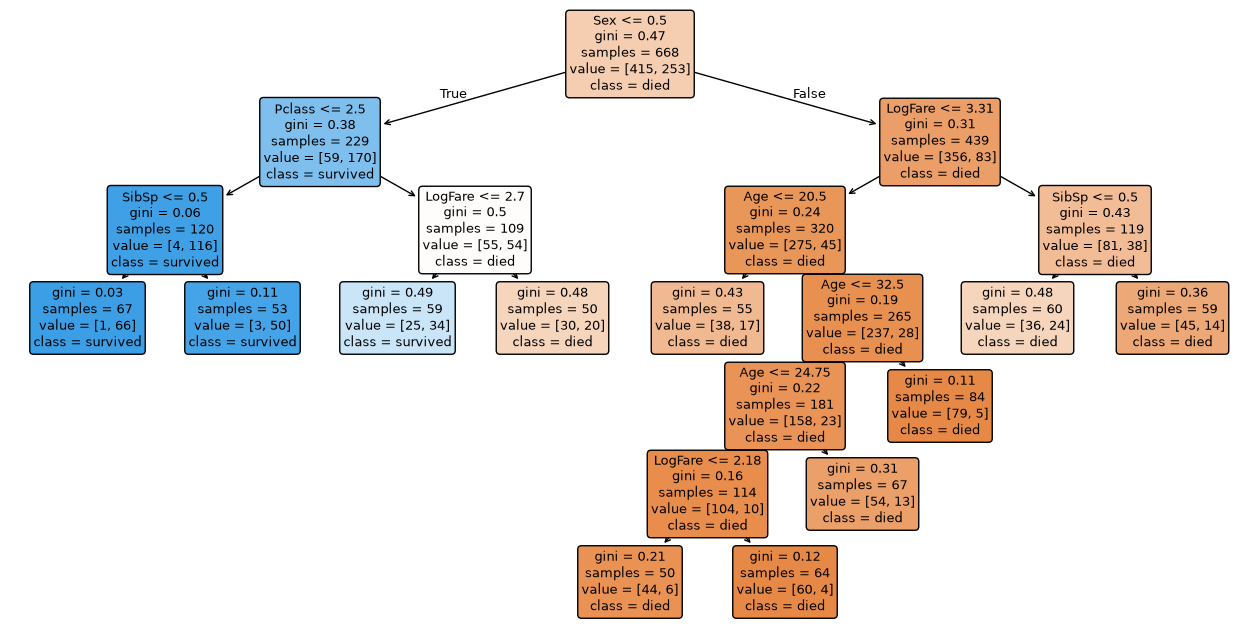

tree50 error: 0.1839


In [32]:
tree50 = DecisionTreeClassifier(min_samples_leaf=50, random_state=42).fit(trn_xs, trn_y)
draw_tree(tree50, trn_xs, size=(16, 8))
tree50_err = mean_absolute_error(val_y, tree50.predict(val_xs))
print("tree50 error:", round(tree50_err, 4))

### Make a Kaggle submission file

We apply the same category-code conversion to the test set, then write the predictions in the format Kaggle expects (`PassengerId`, `Survived`). `subm` will be reused for other models, with a suffix for the file name.

In [35]:
# Convert category columns to integer codes. The 'if' makes this cell safe to re-run:
# once a column is already numbers there is nothing left to convert.
for c in cats:
    if isinstance(tst_df[c].dtype, pd.CategoricalDtype):   # still words (category type)?
        tst_df[c] = tst_df[c].cat.codes                     # words -> integer codes, same categories as training

tst_xs, _ = xs_y(tst_df)                                    # test inputs (there's no answer column, so ignore y)

def subm(preds, suff):
    tst_df['Survived'] = preds                                          # put predictions in a column
    sub_df = tst_df[['PassengerId', 'Survived']]                         # Kaggle wants just these two columns
    sub_df.to_csv(f'sub-{suff}.csv', index=False)                        # e.g. sub-tree.csv

subm(tree50.predict(tst_xs), 'tree')

### A note on category codes
Because trees ask "is the code `<=` something?", a category column with 3 values like `Embarked` (C=0, Q=1, S=2) can only be split as "C vs Q/S" or "C/Q vs S". To isolate "Q" alone the tree would need two splits in a row. For columns with only a few values it can therefore still help to use 0/1 dummy columns. A common rule of thumb: dummies for fewer than about 4 levels, plain codes for 4 or more.

## 7. The random forest

We can't grow one tree much bigger without ending up with tiny groups. A big idea from the statistician Leo Breiman: **train lots of big trees on different random samples of the data and average their predictions.** Averaging many models like this is called **bagging** (bootstrap aggregating).

Why does it work? Each tree makes its own mistakes, and if the trees' mistakes are unrelated (uncorrelated) to each other, they tend to cancel out when averaged, like many people guessing the weight of an ox. The average is more reliable than any one guess. To make the trees different from each other we give each one a different random sample of the training rows.

`get_tree` builds one such tree:
- `rng.choice(n, int(n*prop), replace=True)` picks 75% as many row numbers as there are rows, **with replacement**, so some rows are picked more than once and some not at all. (This resampling trick is called a *bootstrap*.)
- `.iloc[idxs]` selects those rows by position.
- `min_samples_leaf=5` allows much smaller groups than before. Individually these trees overfit a bit, but averaging many of them cancels that out.

In [37]:
rng = np.random.default_rng(42)     # numpy's random number generator, seeded so results repeat

def get_tree(prop=0.75):
    n = len(trn_y)                                          # number of training rows
    idxs = rng.choice(n, int(n * prop), replace=True)       # a random sample of row numbers (a "bootstrap")
    return DecisionTreeClassifier(min_samples_leaf=5, random_state=42).fit(trn_xs.iloc[idxs], trn_y.iloc[idxs])

Create 100 trees (`[get_tree() for t in range(100)]` means "call `get_tree()` 100 times and collect the results"):

In [38]:
trees = [get_tree() for t in range(100)]

Each tree predicts 0 or 1. The **average** of the 100 predictions is the fraction of trees that voted "survived". We predict survived when more than half of the trees agree (`> 0.5`, a majority vote).

- `np.stack(all_votes)` piles the 100 prediction arrays into one 2-D array (trees × passengers),
- `.mean(0)` averages down the tree axis, leaving one number per passenger.

In [39]:
all_votes = [t.predict(val_xs) for t in trees]     # each tree's 0/1 prediction for every validation passenger
avg_votes = np.stack(all_votes).mean(0)            # fraction of the 100 trees that said "survived"
manual_rf_err = mean_absolute_error(val_y, avg_votes > 0.5)
print("hand-made forest error:", round(manual_rf_err, 4))

hand-made forest error: 0.1749


This is almost exactly what scikit-learn's `RandomForestClassifier` does. The one extra ingredient in a "real" random forest: besides giving each tree a random sample of **rows**, it also lets each *split* consider only a random subset of **columns**. That makes the trees even more different from each other, which makes the averaging work better.

- `n_estimators=100` is the number of trees.
- `min_samples_leaf=5` is the same minimum group size as above.
- `.fit(...)` trains all the trees, `.predict(...)` takes the majority vote.

In [40]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=42)
rf.fit(trn_xs, trn_y)
rf_err = mean_absolute_error(val_y, rf.predict(val_xs))
print("random forest error:", round(rf_err, 4))

random forest error: 0.1794


In [41]:
subm(rf.predict(tst_xs), 'rf')    # write sub-rf.csv for Kaggle


### Which columns matter? Feature importance

A very handy by-product of a forest: `feature_importances_` tells us how much each column helped the trees make their splits (the values add up to 1). In a dataset with many columns this is one of the first things worth looking at: it tells you which columns to study more closely.

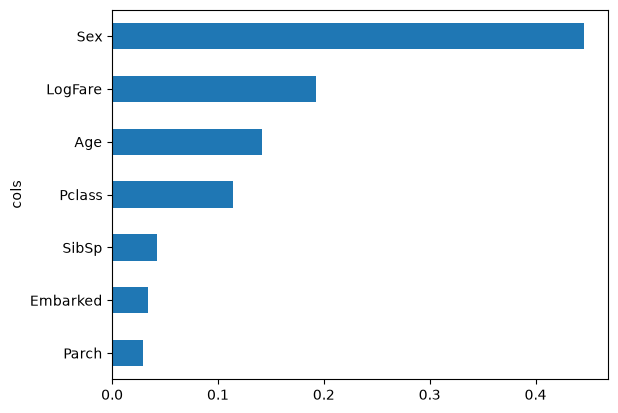

In [42]:
imp = pd.DataFrame(dict(cols=trn_xs.columns, imp=rf.feature_importances_))   # one row per input column
imp.sort_values('imp').plot.barh(x='cols', y='imp', legend=False);           # biggest bar = most important column

Note that we didn't really need `LogFare`: trees only care about *order*, and taking the log doesn't change the order of the fares. We used it earlier only to make the charts easier to read. The same goes for scaling or normalising columns: trees don't need it, which is one reason they are so hard to mess up.

## 8. Putting it together

All the models from this notebook, scored on the **same** validation passengers (lower error is better):

In [43]:
summary = pd.DataFrame({
    "model": ["OneR (one split)", "tree, 4 leaves", "tree, min 50 per leaf", "hand-made forest (100 trees)", "RandomForestClassifier"],
    "validation error": [oner_err, tree4_err, tree50_err, manual_rf_err, rf_err],
})
summary["accuracy"] = 1 - summary["validation error"]      # accuracy = 1 - error rate
summary.round(4)

,model,validation error,accuracy
0,OneR (one split),0.2152,0.7848
1,"tree, 4 leaves",0.2242,0.7758
2,"tree, min 50 per leaf",0.1839,0.8161
3,hand-made forest (100 trees),0.1749,0.8251
4,RandomForestClassifier,0.1794,0.8206


**How to compare with the earlier notebooks.** The from-scratch and fastai notebooks used a different 20% validation split, so their accuracies aren't directly comparable to this table; roughly speaking, they all sit in the same neighbourhood. With only a few hundred validation passengers, differences of a percentage point or two are mostly noise.

## 9. Conclusions

1. **More complex isn't automatically better.** In our run, OneR (a single yes/no question) reached about 0.78 accuracy and the best trees and forests about 0.82. That is a gain of roughly 3-4 percentage points, i.e. 7-9 passengers out of 223. The 100-tree forest was not clearly better than one well-chosen tree (about 1 passenger apart). Always benchmark a simple baseline first: it may already be good enough, and it is much easier to explain and maintain.
2. **Random forests aren't complicated.** We built the core ideas (score a split, find the best one, repeat to make a tree, average many trees) with a few small functions.
3. **Trees are forgiving.** They don't need scaling, dummy columns or log transforms, which makes them quick to use and hard to get wrong. That's why they're so popular for tabular data.
4. **Be careful with small validation sets.** Tiny differences in error between models can be luck.

### Files created
`sub-tree.csv` and `sub-rf.csv` (predictions for the test set). To submit one, upload it on the competition page, or from Python with `kaggle.api.competition_submit("sub-rf.csv", "random forest", "titanic")`.

### Quick glossary
| Term | Plain meaning |
|---|---|
| **Binary split** | sort rows into two groups by "is this column `<=` a threshold?" |
| **Impurity** | how mixed the outcomes in a group are (low = mostly the same) |
| **Gini** | a standard impurity measure: chance that two random rows from a group have different outcomes |
| **OneR** | the model that uses only the single best split |
| **Decision tree** | splits within splits, a flowchart of yes/no questions |
| **Leaf** | an end group of the tree; it makes one prediction |
| **Bagging / bootstrap** | train each model on a random resample of the rows, then average |
| **Random forest** | bagged trees that also use random subsets of columns at each split |
| **Feature importance** | how much each column contributed to the forest's splits |
| **Overfitting** | doing well on training data but worse on new data |